In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, re
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path = "/content/drive/MyDrive/Dataset Big Data/Integrated_Standardized_Earthquake_Catalogue_Indonesia_88AD_2024.csv"
df = pd.read_csv(path, encoding="utf-8-sig", na_values=["NA"],
                 dtype={'Event_ID': str, 'Time_Local': str, 'Region': str, 'Remarks': str})
print("Ukuran data (baris, kolom):", df.shape)
display(df.head(10))
df.info(memory_usage='deep')

Ukuran data (baris, kolom): (322961, 17)


,No,Event_ID,Date,Year,Time_UTC,Time_Local,Latitude,Longitude,Depth_km,Magnitude,Magnitude Type,Catalog_Source,Source_Event_ID,Magnitude_Source/Author,Magnitudo_Relation,Region,Remarks
0,1,0088XXXXXXXXXX,00-000-0088,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-0088-01,NaN,NaN,Java,[Çaka 10] The surface of Java changed its shap...
1,2,0134XXXXXXXXXX,00-000-0134,134,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-0134-01,NaN,NaN,Java,Earthquake and volcanic eruption on Java.
2,3,0296XXXXXXXXXX,00-000-0296,296,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-0296-01,NaN,NaN,Java,"Great upheavals on Java, mountains rise and si..."
3,4,0416XXXXXXXXXX,00-000-0416,416,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-0416-01,NaN,NaN,Krakatau - Java & Sumatera,"[Çaka 338] Earthquake on Java and Sumatra, eru..."
4,5,0444XXXXXXXXXX,00-000-0444,444,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-0444-01,NaN,NaN,Nusa Baron and Nusa Kambangan - Java,The islands of Nusa Baron and Nusa Kambangan a...
5,6,1192XXXXXXXXXX,00-000-1192,1192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-1192-01,NaN,NaN,Palembang - Sumatra,[Çaka 1114] Palembang on Sumatra is separated ...
6,7,1200XXXXXXXXXX,00-000-1200,1200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-1200-01,NaN,NaN,NaN,Separation of Java and Sumatra forming the Sun...
7,8,1242XXXXXXXXXX,00-000-1242,1242,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-1242-01,NaN,NaN,NaN,[Çaka 1164] Pulu Mengari rises from the sea in...
8,9,1254XXXXXXXXXX,00-000-1254,1254,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-1254-01,NaN,NaN,Madura,Hantoro [Madura] is separated from Java.
9,10,1282XXXXXXXXXX,00-000-1282,1282,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Wichmann (1918),W-1282-01,NaN,NaN,Bali,[Çaka 1204] Bali is separated from the Land of...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 322961 entries, 0 to 322960
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   No                       322961 non-null  int64  
 1   Event_ID                 322961 non-null  object 
 2   Date                     322961 non-null  object 
 3   Year                     322961 non-null  int64  
 4   Time_UTC                 321950 non-null  object 
 5   Time_Local               809 non-null     object 
 6   Latitude                 321908 non-null  float64
 7   Longitude                321908 non-null  float64
 8   Depth_km                 321908 non-null  float64
 9   Magnitude                321908 non-null  float64
 10  Magnitude Type           224873 non-null  object 
 11  Catalog_Source           322961 non-null  object 
 12  Source_Event_ID          322961 non-null  object 
 13  Magnitude_Source/Author  321908 non-null  object 
 14  Magn

In [ ]:
mem_awal = df.memory_usage(deep=True).sum() / 1024**2
mem_kolom_awal = df.memory_usage(deep=True)
print(f'Memori awal: {mem_awal:.1f} MB')
print((mem_kolom_awal / 1024**2).round(2).sort_values(ascending=False).head(8).to_string())

Memori awal: 185.3 MB
Source_Event_ID            19.57
Event_ID                   19.40
Date                       17.77
Time_UTC                   17.42
Catalog_Source             16.26
Magnitude_Source/Author    16.23
Magnitudo_Relation         16.09
Region                     14.03


In [ ]:
missing = df.isna().sum()
laporan_missing = pd.DataFrame({
    'jumlah_missing': missing,
    'persen': (missing / len(df) * 100).round(2)
}).sort_values('persen', ascending=False)
laporan_missing

,jumlah_missing,persen
Remarks,322845,99.96
Time_Local,322152,99.75
Magnitudo_Relation,238316,73.79
Region,208955,64.70
Magnitude Type,98088,30.37
Magnitude,1053,0.33
Depth_km,1053,0.33
Latitude,1053,0.33
Longitude,1053,0.33
Magnitude_Source/Author,1053,0.33


In [ ]:
kunci = ['Event_ID','Source_Event_ID','Date','Time_UTC','Latitude','Longitude','Magnitude']
print('Duplikat seluruh kolom (tanpa kolom No):', df.drop(columns='No').duplicated().sum())
print('Duplikat kombinasi kunci               :', df.duplicated(subset=kunci).sum())
print('Event_ID berulang                      :', df['Event_ID'].duplicated().sum())
print('Source_Event_ID berulang               :', df['Source_Event_ID'].duplicated().sum())

Duplikat seluruh kolom (tanpa kolom No): 0
Duplikat kombinasi kunci               : 0
Event_ID berulang                      : 248
Source_Event_ID berulang               : 186


In [ ]:
def batas_iqr(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

hasil_outlier = []
for kolom in ['Magnitude', 'Depth_km']:
    bawah, atas = batas_iqr(df[kolom].dropna())
    out = df[(df[kolom] < bawah) | (df[kolom] > atas)]
    hasil_outlier.append({'kolom': kolom, 'batas_bawah': round(bawah, 4), 'batas_atas': round(atas, 4),
                          'jumlah_outlier': len(out), 'persen': round(len(out) / len(df) * 100, 3)})
display(pd.DataFrame(hasil_outlier))

bawah, atas = batas_iqr(df['Depth_km'].dropna())
out = df[(df['Depth_km'] < bawah) | (df['Depth_km'] > atas)]
display(out.groupby('Catalog_Source').size().reset_index(name='jumlah_outlier_depth'))
display(df[['Magnitude', 'Depth_km']].describe())

,kolom,batas_bawah,batas_atas,jumlah_outlier,persen
0,Magnitude,0.45,6.45,479,0.148
1,Depth_km,-65.00,135.00,38079,11.791


,Catalog_Source,jumlah_outlier_depth
0,BMKG,18786
1,GFZ,5
2,ISC,18921
3,ISC; Martin et al. (2022),19
4,USGS,348


,Magnitude,Depth_km
count,321908.000000,321908.000000
mean,3.440453,56.480803
std,0.952124,88.980874
min,0.000000,1.000000
25%,2.700000,10.000000
50%,3.400000,24.000000
75%,4.200000,60.000000
max,8.200000,798.000000


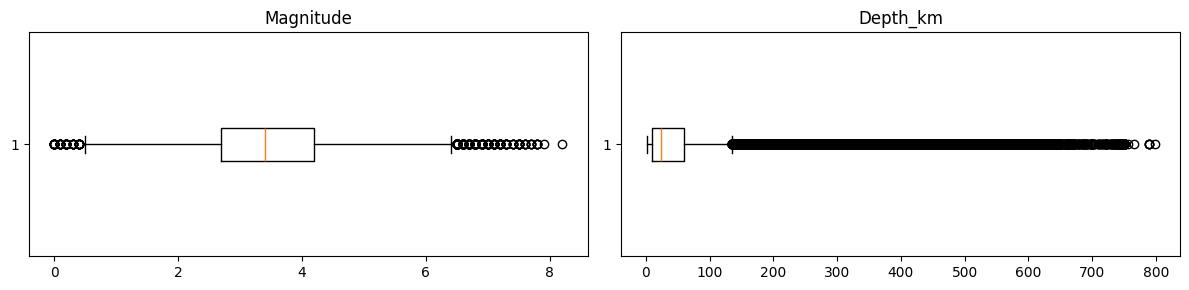

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].boxplot(df['Magnitude'].dropna(), vert=False); ax[0].set_title('Magnitude')
ax[1].boxplot(df['Depth_km'].dropna(), vert=False); ax[1].set_title('Depth_km')
plt.tight_layout(); plt.show()

In [ ]:
kolom_teks = ['Catalog_Source', 'Magnitude Type', 'Magnitude_Source/Author', 'Magnitudo_Relation', 'Region']
cek_teks = pd.DataFrame({
    'nunique': [df[k].nunique() for k in kolom_teks],
    'spasi_tepi': [(df[k].dropna() != df[k].dropna().str.strip()).sum() for k in kolom_teks],
    'spasi_ganda': [df[k].str.contains('  ', na=False).sum() for k in kolom_teks],
}, index=kolom_teks)
display(cek_teks)

mt = df['Magnitude Type'].dropna()
print('Magnitude Type unik:', mt.nunique(), '| jika huruf disamakan:', mt.str.lower().nunique())
print(df['Catalog_Source'].value_counts())
print('Contoh format Date data sejarah :', df.loc[df['Latitude'].isna(), 'Date'].iloc[0])
print('Contoh format Date data modern  :', df['Date'].iloc[-1])

,nunique,spasi_tepi,spasi_ganda
Catalog_Source,8,985,0
Magnitude Type,26,0,0
Magnitude_Source/Author,42,0,0
Magnitudo_Relation,50806,0,0
Region,156,0,1


Magnitude Type unik: 26 | jika huruf disamakan: 18
Catalog_Source
BMKG                          235501
ISC                            84330
USGS                            1852
Martin et al. (2022)             985
ISC; Martin et al. (2022)        141
Wichmann (1918)                   68
USGS; Martin et al. (2022)        65
GFZ                               19
Name: count, dtype: int64
Contoh format Date data sejarah : 00-000-0088
Contoh format Date data modern  : 31-Dec-24


In [ ]:
print('Baris awal                                  :', len(df))
print('Sisa jika dropna() seluruh kolom            :', len(df.dropna()))
print('Sisa jika dropna(subset 4 kolom utama)      :',
      len(df.dropna(subset=['Latitude', 'Longitude', 'Depth_km', 'Magnitude'])))

Baris awal                                  : 322961
Sisa jika dropna() seluruh kolom            : 0
Sisa jika dropna(subset 4 kolom utama)      : 321908


In [ ]:
# a. Catatan sejarah (tanpa koordinat) dipisah, tidak diimputasi
df_sejarah = df[df['Latitude'].isna()].copy()
df = df[df['Latitude'].notna()].copy().reset_index(drop=True)
print('Catatan sejarah dipisah:', len(df_sejarah), '| Data instrumental:', len(df))

# b. Kolom nyaris kosong dihapus
df = df.drop(columns=['Remarks', 'Time_Local'])

# c. Kategorikal kosong diisi konstanta
for k in ['Region', 'Magnitude Type', 'Magnitudo_Relation']:
    df[k] = df[k].fillna('Tidak diketahui')

print(df.isna().sum())

Catatan sejarah dipisah: 1053 | Data instrumental: 321908
No                         0
Event_ID                   0
Date                       0
Year                       0
Time_UTC                   0
Latitude                   0
Longitude                  0
Depth_km                   0
Magnitude                  0
Magnitude Type             0
Catalog_Source             0
Source_Event_ID            0
Magnitude_Source/Author    0
Magnitudo_Relation         0
Region                     0
dtype: int64


In [ ]:
rng = np.random.default_rng(42)
asli = df[['Catalog_Source', 'Depth_km']].copy()
sim = asli.copy()
idx = sim.index[rng.choice(len(sim), size=int(0.02 * len(sim)), replace=False)]
sim.loc[idx, 'Depth_km'] = np.nan
print('Missing buatan:', sim['Depth_km'].isna().sum())

isi_mean = sim['Depth_km'].fillna(sim['Depth_km'].mean())
isi_median = sim['Depth_km'].fillna(sim['Depth_km'].median())
isi_grup = sim['Depth_km'].fillna(sim.groupby('Catalog_Source')['Depth_km'].transform('median'))

hasil_sim = pd.DataFrame({
    'strategi': ['A. mean global', 'B. median global', 'C. median per Catalog_Source'],
    'galat_rata2_km': [(x.loc[idx] - asli.loc[idx, 'Depth_km']).abs().mean()
                       for x in [isi_mean, isi_median, isi_grup]]
}).round(2)
hasil_sim

Missing buatan: 6438


,strategi,galat_rata2_km
0,A. mean global,54.42
1,B. median global,44.77
2,C. median per Catalog_Source,41.65


In [ ]:
deret = pd.Series([10, np.nan, np.nan, 40, np.nan, 60])
print(deret.interpolate(method='linear'))

0    10.0
1    20.0
2    30.0
3    40.0
4    50.0
5    60.0
dtype: float64


In [ ]:
sebelum = len(df)
df = df.drop_duplicates(subset=kunci, keep='first').reset_index(drop=True)
print(f'Dihapus: {sebelum - len(df):,} baris | Sisa: {len(df):,}')
print('Event_ID masih berulang (bukan duplikat sejati):', df['Event_ID'].duplicated().sum())

Dihapus: 0 baris | Sisa: 321,908
Event_ID masih berulang (bukan duplikat sejati): 239


In [ ]:
for k in kolom_teks:
    df[k] = df[k].str.strip().str.replace(r'\s+', ' ', regex=True)

print(df['Catalog_Source'].value_counts())
print('Magnitude Type unik:', df['Magnitude Type'].nunique())

Catalog_Source
BMKG                          235501
ISC                            84330
USGS                            1852
ISC; Martin et al. (2022)        141
USGS; Martin et al. (2022)        65
GFZ                               19
Name: count, dtype: int64
Magnitude Type unik: 27


In [ ]:
parts = df['Date'].str.split('-', expand=True)
tgl = parts[0] + '-' + parts[1] + '-' + df['Year'].astype(str)   # pakai Year (4 digit)
df['tanggal'] = pd.to_datetime(tgl, format='%d-%b-%Y', errors='coerce')
print('Gagal parse tanggal:', df['tanggal'].isna().sum())

df['bulan'] = df['tanggal'].dt.month.astype('Int8')
df['hari'] = df['tanggal'].dt.day_name()
waktu = df['Time_UTC'].str.extract(r'(\d{1,2}):(\d{2})')
df['jam'] = pd.to_numeric(waktu[0], errors='coerce').astype('Int8')
df['menit'] = pd.to_numeric(waktu[1], errors='coerce').astype('Int8')

df = df.drop(columns=['Date', 'Time_UTC'])   # sudah terwakili tanggal, jam, menit
df[['tanggal', 'bulan', 'hari', 'jam', 'menit']].head()

Gagal parse tanggal: 0


,tanggal,bulan,hari,jam,menit
0,1905-01-22,1,Sunday,2,43
1,1905-09-29,9,Friday,11,52
2,1906-06-01,6,Friday,4,30
3,1906-10-28,10,Sunday,15,50
4,1906-10-29,10,Monday,1,15


In [ ]:
# Kolom berulang -> category
for k in ['Catalog_Source', 'Magnitude Type', 'Magnitude_Source/Author', 'Magnitudo_Relation', 'Region', 'hari']:
    df[k] = df[k].astype('category')

# Kolom ID hampir unik: category tidak efektif, pakai string arrow
for k in ['Event_ID', 'Source_Event_ID']:
    df[k] = df[k].astype('string[pyarrow]')

# Downcasting numerik
for k in ['Latitude', 'Longitude', 'Depth_km', 'Magnitude']:
    df[k] = pd.to_numeric(df[k], downcast='float')
df['Year'] = df['Year'].astype('int16')
df['No'] = pd.to_numeric(df['No'], downcast='integer')

In [ ]:
mem_akhir = df.memory_usage(deep=True).sum() / 1024**2
print(f'Awal : {mem_awal:.1f} MB')
print(f'Akhir: {mem_akhir:.1f} MB')
print(f'Hemat: {(1 - mem_akhir / mem_awal) * 100:.1f}%')

t = pd.DataFrame({'awal_MB': mem_kolom_awal / 1024**2,
                  'akhir_MB': df.memory_usage(deep=True) / 1024**2}).dropna()
t['hemat_%'] = (1 - t['akhir_MB'] / t['awal_MB']) * 100
display(t.round(2).sort_values('awal_MB', ascending=False))

Awal : 185.3 MB
Akhir: 36.1 MB
Hemat: 80.5%


,awal_MB,akhir_MB,hemat_%
Source_Event_ID,19.57,6.93,64.61
Event_ID,19.40,6.75,65.19
Catalog_Source,16.26,0.31,98.11
Magnitude_Source/Author,16.23,0.31,98.09
Magnitudo_Relation,16.09,9.83,38.90
Region,14.03,0.31,97.76
Magnitude Type,14.00,0.31,97.79
Longitude,2.46,1.23,50.16
Latitude,2.46,1.23,50.16
Depth_km,2.46,1.23,50.16


In [ ]:
df.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 321908 entries, 0 to 321907
Data columns (total 18 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   No                       321908 non-null  int32         
 1   Event_ID                 321908 non-null  string        
 2   Year                     321908 non-null  int16         
 3   Latitude                 321908 non-null  float32       
 4   Longitude                321908 non-null  float32       
 5   Depth_km                 321908 non-null  float32       
 6   Magnitude                321908 non-null  float32       
 7   Magnitude Type           321908 non-null  category      
 8   Catalog_Source           321908 non-null  category      
 9   Source_Event_ID          321908 non-null  string        
 10  Magnitude_Source/Author  321908 non-null  category      
 11  Magnitudo_Relation       321908 non-null  category      
 12  Region          

In [ ]:
bawah, atas = batas_iqr(df['Depth_km'])
df['Depth_km_winsor'] = df['Depth_km'].clip(lower=max(bawah, 0), upper=atas)
display(df[['Depth_km', 'Depth_km_winsor']].describe().round(2))

,Depth_km,Depth_km_winsor
count,321908.00,321908.00
mean,56.48,43.23
std,88.97,44.12
min,1.00,1.00
25%,10.00,10.00
50%,24.00,24.00
75%,60.00,60.00
max,798.00,135.00


In [ ]:
# Manual
d = df['Depth_km_winsor']
df['depth_minmax'] = (d - d.min()) / (d.max() - d.min())
df['depth_zscore'] = (d - d.mean()) / d.std()

m = df['Magnitude']
df['mag_minmax'] = (m - m.min()) / (m.max() - m.min())
df['mag_zscore'] = (m - m.mean()) / m.std()

# Dengan scikit-learn (kolom Year)
from sklearn.preprocessing import MinMaxScaler, StandardScaler
df['year_minmax'] = MinMaxScaler().fit_transform(df[['Year']]).ravel()
df['year_zscore'] = StandardScaler().fit_transform(df[['Year']]).ravel()

kolom_skala = [c for c in df.columns if c.endswith(('_minmax', '_zscore'))]
display(df[kolom_skala].describe().round(3))

,depth_minmax,depth_zscore,mag_minmax,mag_zscore,year_minmax,year_zscore
count,321908.000,321908.000,321908.000,321908.000,321908.000,321908.000
mean,0.315,-0.000,0.420,-0.000,0.917,-0.000
std,0.329,0.999,0.116,1.000,0.099,1.000
min,0.000,-0.957,0.000,-3.614,0.000,-9.292
25%,0.067,-0.753,0.329,-0.778,0.882,-0.349
50%,0.172,-0.436,0.415,-0.042,0.958,0.418
75%,0.440,0.380,0.512,0.798,0.983,0.674
max,1.000,2.080,1.000,5.000,1.000,0.844


In [ ]:
print(df[[c for c in kolom_skala if c.endswith('_minmax')]].agg(['min', 'max']).round(3))
print(df[[c for c in kolom_skala if c.endswith('_zscore')]].agg(['mean', 'std']).round(3))

     depth_minmax  mag_minmax  year_minmax
min           0.0         0.0          0.0
max           1.0         1.0          1.0
      depth_zscore  mag_zscore  year_zscore
mean        -0.000        -0.0         -0.0
std          0.999         1.0          1.0


In [ ]:
# Ordinal: kelas magnitudo punya urutan
df['kelas_magnitudo'] = pd.cut(df['Magnitude'], bins=[0, 3, 4, 5, 6, 10],
                               labels=['Sangat kecil', 'Kecil', 'Sedang', 'Kuat', 'Besar'],
                               include_lowest=True)
df['kelas_kode'] = df['kelas_magnitudo'].cat.codes.astype('int8')

# Label encoding: Region (banyak nilai)
df['region_kode'] = df['Region'].cat.codes.astype('int16')

# One-hot: Catalog_Source (8 nilai, tanpa urutan)
dummies = pd.get_dummies(df['Catalog_Source'], prefix='src', dtype='int8')
df = pd.concat([df, dummies], axis=1)

display(df.filter(like='src_').head())
display(df[['kelas_magnitudo', 'kelas_kode']].drop_duplicates().sort_values('kelas_kode'))
display(df['kelas_magnitudo'].value_counts())

,src_BMKG,src_GFZ,src_ISC,src_ISC; Martin et al. (2022),src_USGS,src_USGS; Martin et al. (2022)
0,0,0,0,1,0,0
1,0,0,0,0,0,1
2,0,0,0,0,1,0
3,0,0,0,0,0,1
4,0,0,0,0,1,0


,kelas_magnitudo,kelas_kode
13,Sangat kecil,0
848,Kecil,1
802,Sedang,2
3,Kuat,3
0,Besar,4


,count
kelas_magnitudo,
Sangat kecil,124287
Kecil,108020
Sedang,74805
Kuat,13697
Besar,1099


In [ ]:
stopword = {'indonesia', 'region'}

def bersihkan_teks(teks):
    teks = str(teks).lower()                       # case folding
    teks = re.sub(r'http[^ ]+|www[^ ]+', ' ', teks)  # hapus URL
    teks = re.sub(r'#[a-z0-9_]+', ' ', teks)         # hapus hashtag
    teks = re.sub(r'[^a-z ]', ' ', teks)             # hapus tanda baca, angka
    teks = re.sub(r' +', ' ', teks).strip()          # rapikan spasi
    kata = [k for k in teks.split(' ') if k and k not in stopword]
    return ' '.join(kata)

contoh = ['Sulawesi, Indonesia', 'Minahassa Peninsula, Sulawesi', 'Sumbawa Region, Indonesia', 'Banda Sea']
for c in contoh:
    print(repr(c), '->', repr(bersihkan_teks(c)))

'Sulawesi, Indonesia' -> 'sulawesi'
'Minahassa Peninsula, Sulawesi' -> 'minahassa peninsula sulawesi'
'Sumbawa Region, Indonesia' -> 'sumbawa'
'Banda Sea' -> 'banda sea'


In [ ]:
unik = df['Region'].astype(str).unique()
peta = {u: bersihkan_teks(u) for u in unik}
df['region_bersih'] = df['Region'].astype(str).map(peta).astype('category')

print('Nilai unik sebelum:', df['Region'].nunique(), '| sesudah:', df['region_bersih'].nunique())
display(df[['Region', 'region_bersih']].drop_duplicates().head(10))

Nilai unik sebelum: 89 | sesudah: 81


,Region,region_bersih
0,Tidak diketahui,tidak diketahui
12,Sulawesi (Palu-Koro),sulawesi palu koro
13,Sumatra,sumatra
15,South Maluku,south maluku
16,Sulawesi (Minahassa),sulawesi minahassa
22,Java,java
23,Mindanao (Philippines),mindanao philippines
28,Lesser Sunda Islands,lesser sunda islands
31,Sulawesi (Gulf of Tomini?),sulawesi gulf of tomini
32,Sanghie-Talaud Islands,sanghie talaud islands


In [ ]:
def bersihkan_gempa(path_csv):
    d = pd.read_csv(path_csv, encoding='utf-8-sig', na_values=['NA'],
                    dtype={'Event_ID': str, 'Time_Local': str, 'Region': str, 'Remarks': str})
    # missing
    d = d[d['Latitude'].notna()].drop(columns=['Remarks', 'Time_Local']).copy()
    for k in ['Region', 'Magnitude Type', 'Magnitudo_Relation']:
        d[k] = d[k].fillna('Tidak diketahui')
    # duplikasi dan teks
    d = d.drop_duplicates(subset=kunci).reset_index(drop=True)
    for k in kolom_teks:
        d[k] = d[k].str.strip().str.replace(r'\s+', ' ', regex=True)
    # tanggal dan waktu
    tgl = d['Date'].str.split('-', expand=True)
    d['tanggal'] = pd.to_datetime(tgl[0] + '-' + tgl[1] + '-' + d['Year'].astype(str),
                                  format='%d-%b-%Y', errors='coerce')
    d['bulan'] = d['tanggal'].dt.month.astype('Int8')
    d['hari'] = d['tanggal'].dt.day_name()
    w = d['Time_UTC'].str.extract(r'(\d{1,2}):(\d{2})')
    d['jam'] = pd.to_numeric(w[0], errors='coerce').astype('Int8')
    d['menit'] = pd.to_numeric(w[1], errors='coerce').astype('Int8')
    d = d.drop(columns=['Date', 'Time_UTC'])
    # tipe data
    for k in ['Latitude', 'Longitude', 'Depth_km', 'Magnitude']:
        d[k] = pd.to_numeric(d[k], downcast='float')
    d['Year'] = d['Year'].astype('int16')
    d['No'] = pd.to_numeric(d['No'], downcast='integer')
    # outlier dan skala
    b, a = batas_iqr(d['Depth_km'])
    d['Depth_km_winsor'] = d['Depth_km'].clip(lower=max(b, 0), upper=a)
    x = d['Depth_km_winsor']
    d['depth_minmax'] = (x - x.min()) / (x.max() - x.min())
    d['depth_zscore'] = (x - x.mean()) / x.std()
    y = d['Magnitude']
    d['mag_minmax'] = (y - y.min()) / (y.max() - y.min())
    d['mag_zscore'] = (y - y.mean()) / y.std()
    # encoding
    d['kelas_magnitudo'] = pd.cut(d['Magnitude'], bins=[0, 3, 4, 5, 6, 10],
                                  labels=['Sangat kecil', 'Kecil', 'Sedang', 'Kuat', 'Besar'],
                                  include_lowest=True)
    d = pd.concat([d, pd.get_dummies(d['Catalog_Source'], prefix='src', dtype='int8')], axis=1)
    # teks bersih
    peta_r = {u: bersihkan_teks(u) for u in d['Region'].astype(str).unique()}
    d['region_bersih'] = d['Region'].astype(str).map(peta_r)
    # category dan string arrow
    for k in ['Catalog_Source', 'Magnitude Type', 'Magnitude_Source/Author', 'Magnitudo_Relation',
              'Region', 'hari', 'region_bersih']:
        d[k] = d[k].astype('category')
    for k in ['Event_ID', 'Source_Event_ID']:
        d[k] = d[k].astype('string[pyarrow]')
    return d

In [ ]:
hasil = bersihkan_gempa(path)
print(hasil.shape)
print('Jumlah baris sama      :', len(hasil) == len(df))
print('Depth_km_winsor sama   :', np.allclose(hasil['Depth_km_winsor'], df['Depth_km_winsor']))
print('region_bersih sama     :', (hasil['region_bersih'].astype(str) == df['region_bersih'].astype(str)).all())
print(f"Memori hasil fungsi    : {hasil.memory_usage(deep=True).sum() / 1024**2:.1f} MB (awal {mem_awal:.1f} MB)")

(321908, 31)
Jumlah baris sama      : True
Depth_km_winsor sama   : True
region_bersih sama     : True
Memori hasil fungsi    : 44.7 MB (awal 185.3 MB)


In [ ]:
folder = '/content/drive/MyDrive/Dataset Big Data/output'
os.makedirs(folder, exist_ok=True)
out_pq = folder + '/gempa_bersih.parquet'
hasil.to_parquet(out_pq, index=False)

ukuran_csv = os.path.getsize(path) / 1024**2
ukuran_pq = os.path.getsize(out_pq) / 1024**2
print(f'CSV mentah : {ukuran_csv:.2f} MB')
print(f'Parquet    : {ukuran_pq:.2f} MB')
print(f'Hemat      : {(1 - ukuran_pq / ukuran_csv) * 100:.1f}%')

cek = pd.read_parquet(out_pq)
print(cek.shape)
print(cek.dtypes)
print('Sisa missing:', cek.isna().sum().sum())

CSV mentah : 39.17 MB
Parquet    : 12.43 MB
Hemat      : 68.3%
(321908, 31)
No                                         int32
Event_ID                          string[python]
Year                                       int16
Latitude                                 float32
Longitude                                float32
Depth_km                                 float32
Magnitude                                float32
Magnitude Type                          category
Catalog_Source                          category
Source_Event_ID                   string[python]
Magnitude_Source/Author                 category
Magnitudo_Relation                      category
Region                                  category
tanggal                           datetime64[ns]
bulan                                       Int8
hari                                    category
jam                                         Int8
menit                                       Int8
Depth_km_winsor                          f